# Decision Trees vs. Random Forest for Regression

Why does a Random Forest usually beat a single decision tree? This notebook shows it on a
real regression task (scikit-learn's diabetes dataset: predict disease progression one year
after baseline from 10 clinical features), step by step:

1. A single decision tree and how it **overfits** as depth grows
2. A Random Forest and why averaging many trees reduces variance
3. Cross-validated comparison
4. Hyperparameter tuning with `RandomizedSearchCV`
5. Feature importance

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

SEED = 42
data = load_diabetes(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print(X.shape, "features:", list(X.columns))

(442, 10) features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## 1. A single decision tree overfits as it gets deeper

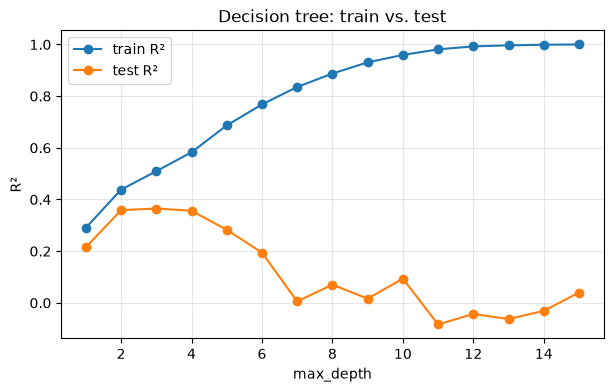

Best depth on test: 3 (test R² = 0.365); fully grown tree train R² = 1.000, test R² = 0.040


In [2]:
depths = range(1, 16)
train_r2, test_r2 = [], []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train)
    train_r2.append(tree.score(X_train, y_train))
    test_r2.append(tree.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_r2, marker="o", label="train R²")
plt.plot(depths, test_r2, marker="o", label="test R²")
plt.xlabel("max_depth"); plt.ylabel("R²"); plt.title("Decision tree: train vs. test"); plt.legend(); plt.grid(alpha=.3)
plt.show()
best_depth = depths[int(np.argmax(test_r2))]
print(f"Best depth on test: {best_depth} (test R² = {max(test_r2):.3f}); fully grown tree train R² = {train_r2[-1]:.3f}, test R² = {test_r2[-1]:.3f}")

Training R² keeps climbing toward 1.0 while test R² stalls or drops: the tree is memorizing the training data (high variance).

In [3]:
tree = DecisionTreeRegressor(random_state=SEED).fit(X_train, y_train)
forest = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train, y_train)

rows = []
for name, model in [("Decision tree (full depth)", tree), ("Random Forest (300 trees)", forest)]:
    pred = model.predict(X_test)
    rows.append({"model": name, "test R²": r2_score(y_test, pred), "test MAE": mean_absolute_error(y_test, pred)})
pd.DataFrame(rows).round(3)

,model,test R²,test MAE
0,Decision tree (full depth),-0.075,58.838
1,Random Forest (300 trees),0.474,43.096


## 3. Cross-validated comparison

A single train/test split can be lucky. 5-fold cross-validation is more reliable.

In [4]:
cv_tree = cross_val_score(DecisionTreeRegressor(random_state=SEED), X, y, cv=5, scoring="r2")
cv_rf = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), X, y, cv=5, scoring="r2")
print(f"Decision tree : R² = {cv_tree.mean():.3f} ± {cv_tree.std():.3f}")
print(f"Random Forest : R² = {cv_rf.mean():.3f} ± {cv_rf.std():.3f}")

Decision tree : R² = -0.145 ± 0.082
Random Forest : R² = 0.421 ± 0.051


## 4. Hyperparameter tuning

In [5]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 3, 5, 8, 12],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", 0.5, 1.0],
}
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1), param_dist,
    n_iter=25, cv=5, scoring="r2", random_state=SEED, n_jobs=-1,
).fit(X_train, y_train)
best = search.best_estimator_
pred = best.predict(X_test)
print("Best params:", search.best_params_)
print(f"Tuned forest on held-out test: R² = {r2_score(y_test, pred):.3f}, MAE = {mean_absolute_error(y_test, pred):.1f}")

Best params: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 5}
Tuned forest on held-out test: R² = 0.511, MAE = 41.6


## 5. Feature importance

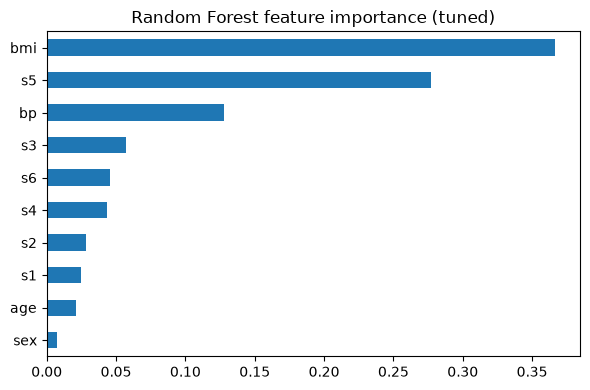

bmi    0.366
s5     0.277
bp     0.128
s3     0.057
s6     0.046
s4     0.043
s2     0.028
s1     0.025
age    0.021
sex    0.008
dtype: float64

In [6]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(6, 4), title="Random Forest feature importance (tuned)"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

## Takeaways

- A fully grown decision tree fits the training set perfectly and generalizes poorly.
- Averaging many decorrelated trees (bagging + random feature subsets) cuts variance and
  improves out-of-sample error without tuning much.
- Limiting depth and leaf size through search regularizes the forest further.
- Feature importance gives a quick, model-based view of which variables drive the target.

*Author: Márcio Belloni.* Re-run with `pip install -r requirements.txt` and `jupyter notebook`.